# Complementary Dimensions: Salience and Thematic Content
- Original Tool from SIBling: https://aclanthology.org/2024.acl-long.76/ (adapted for this study)
- **Author:** Naomi Baes

In [12]:
#!pip install spacy
#!pip install ipywidgets
#!jupyter nbextension enable --py widgetsnbextension

## Salience: Compute Annual Article Target Relative Frequency

This script gets counts of articles containing the target term divided by the total number of annual articles in the corpus (database).

In [1]:
%run 3_step1_target_annual_article_relative_frequency.py

Saved proportion file to: output/rel_freq_text_counts_byyear_ADHD.csv


In [2]:
# inspect input files briefly
# === Load files ===
df_target = pd.read_csv(target_file)
df_total  = pd.read_csv(total_file)

# === Quick sanity check: show heads ===
print("▶ Head of target counts by year:")
print(df_target.head(), "\n")

print("▶ Head of total article counts by year:")
print(df_total.head(), "\n")

▶ Head of target counts by year:
   year  count
0  1980      1
1  1983      2
2  1985      7
3  1986      5
4  1987     34 

▶ Head of total article counts by year:
   year    count
0  1980  118,739
1  1981  144,804
2  1982  137,489
3  1983  228,317
4  1984  390,550 



✓ Saved plot to: output/ADHD_rel_freq_by_year.png


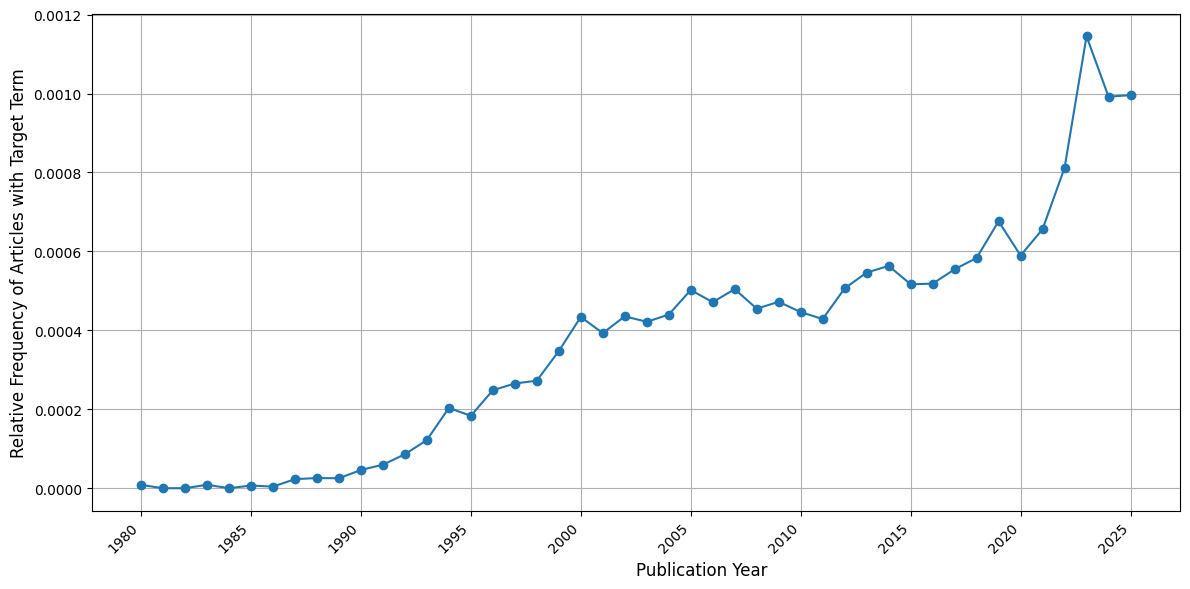

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# ——— Paths ———
proportion_csv = 'output/rel_freq_text_counts_byyear_ADHD.csv'
plot_png       = os.path.join(os.path.dirname(proportion_csv), 'ADHD_rel_freq_by_year.png')

# ——— Load data ———
df = pd.read_csv(proportion_csv)
df['year'] = df['year'].astype(int)
df = df.sort_values('year')

# ——— Plot ———
plt.figure(figsize=(12, 6))
plt.plot(df['year'], df['proportion'], marker='o')
plt.xlabel('Publication Year', fontsize=12, ha='left')
plt.ylabel('Relative Frequency of Articles with Target Term', fontsize=12)
plt.xticks(df['year'][::5], rotation=45, ha='right')  # every 5th year
plt.grid(True)
plt.tight_layout()

# ——— Save & show ———
plt.savefig(plot_png)
print(f"✓ Saved plot to: {plot_png}")
plt.show()

## Thematic Content

### Collocates (Top-Ranked Co-occurrences) by Decade

- **Local Association Measure**  
  $$\mathrm{normalized\_count}_{w,c}
    = \frac{\mathrm{co\text{-}occurrence\ count}_{w,c}}
           {\sum_{c'}\mathrm{co\text{-}occurrence\ count}_{w,c'}}$$

- **Purpose**  
  Quickly shows which collocates dominate your target’s contexts in each decade—  
  i.e. “Of all the times my target appears, what fraction involve \(c\)?”

- **When to use**  
  - Ideal for a first-pass, interpretable ranking of prominent co-occurrences in a subset.  
  - **Note:** It does **not** account for background frequencies, so very common words may still surface.

**Step-by-step:**
1. **Load files** from `output/cooccurrences_by_year/`.
2. **Extract year** from filename → convert to **decade**.
3. **Read each file**, line-by-line:
   - Get `cooccurrence`, `count`
   - Add count to `decade_cooccurrences[decade][cooccurrence]`
4. **Remove stop words** Remove stop words using the NLTK english stop word list (see below)
5. For each **decade**:
   - Select top `n` cooccurrences by count.
   - Normalize count by total cooccurrence counts in that decade.
6. **Save output** as `output/{target}_top_cooccurrences_by_decade.csv`.      [INSPECT THESE OUTPUT FILES]

nltk english stop word list location: https://github.com/nltk/nltk_data/blob/gh-pages/packages/corpora/stopwords.zip
Note: We use the version Steven Bird uploaded on 10/03/2025

In [4]:
#%run 3_step2_top-ranked_cooccurrences_year.py # see output (NOTE: NO STOPWORDS REMOVED HERE)
#%run 3_step2_top-ranked_cooccurrences_decade.py # see output (NOTE: NO STOPWORDS REMOVED HERE)
%run 3_step2_top-ranked_cooccurrences_decade_stopwords.py # filter cooccurrences from stop word list before getting top-ranked cooccurrences

✔ Saved: output/ADHD_top_cooccurrences_by_decade_nostopwords.csv


### Cluster sentence-level embeddings to trace shifting sense usages of the target

### Step A: Cluster XLL sentence vectors and save

**Goal**: Discover recurring *sense clusters / themes* in every sentence that contains the target word using the 1024-dim XL-LEXEME sentence vectors we saved earlier.

The script loads all yearly XL-LEXEME sentence-vectors for one target word, trims years with very few sentences and caps each year to a maximum sample (to keep clusters balanced), stacks everything into one big matrix, optionally runs a 100-dim PCA for speed, and grid searches k = 3...16 and keeps the k with the highest average Silhouette score.
It then:
1) assigns every sentence to its cluster (so you can inspect or trace them later)
2) saves the XL-LEXEME centroid vectors (one sense prototype per cluster)
3) extracts *differential* TF-IDF “top terms” per cluster for an at-a-glance theme label
4) writes three artefacts into thematic_content/cluster_XLL_embeddings/
- sentences_with_clusters.csv – year, line-index, raw sentence, cluster id
- kmeans_centroids.npy – k × 1024 centroid matrix
- tfidf_top_terms.json – top N keywords per cluster (+ small meta.json)

…so you can immediately:
peek at 10 example sentences nearest each centroid,
search “nearest neighbours” to any query sentence, or
track how the share of each sense-cluster shifts over decades / feed the centroids into other classifiers.

**NOTE**: If the TF-IDF labels are **insufficiently discriminative**, you can experiment with SVD or LSA (vs TF-IDF) if there are highly overlapping themes (i.e., the clusters share a lot of vocab). TF-IDF treats every unique word equally so if clusters have noisy or very rare words, SVD (LSA) can denoise by emphasizing shared patterns of co-occurrence. SVD gives component loadings that you can compare numerically (e.g., how strongly does cluster 3 load on topic 1 vs. topic 2)?
- Can also swap k-means clustering for UDMAP

#### Step 1: Embed all sentences in corpus containing target term using XLL

In [9]:
import os
import pandas as pd

# Load the full dataset
df = pd.read_csv("output/ADHD_News_fulltext_normalized-ADHD_sentences_cleaned.csv", sep=",")

# Output directory
output_dir = "output/embeddings/sentences_all"
os.makedirs(output_dir, exist_ok=True)

target = "adhd"

# ----- loop over years -------------------------------------------------
for year, group in df.groupby("year"):
    # drop duplicates *within* that year
    unique_sents = group["raw_sent"].drop_duplicates()

    # report how many went out
    n_out = len(unique_sents)
    print(f"Writing {n_out} sentences for {year}…")

    # write one *.txt file per year (UTF-8, one sentence per line)
    filename   = f"{target}_raw-sentence_US_Newsstream_{year}.txt"
    output_path = os.path.join(output_dir, filename)

    with open(output_path, "w", encoding="utf-8") as f:
        for sent in unique_sents:
            f.write(sent.strip() + "\n")

Writing 2 sentences for 1980…
Writing 4 sentences for 1983…
Writing 8 sentences for 1985…
Writing 5 sentences for 1986…
Writing 67 sentences for 1987…
Writing 65 sentences for 1988…
Writing 85 sentences for 1989…
Writing 254 sentences for 1990…
Writing 253 sentences for 1991…
Writing 358 sentences for 1992…
Writing 549 sentences for 1993…
Writing 785 sentences for 1994…
Writing 986 sentences for 1995…
Writing 1455 sentences for 1996…
Writing 1394 sentences for 1997…
Writing 1837 sentences for 1998…
Writing 2610 sentences for 1999…
Writing 3672 sentences for 2000…
Writing 3170 sentences for 2001…
Writing 3081 sentences for 2002…
Writing 3408 sentences for 2003…
Writing 3617 sentences for 2004…
Writing 4527 sentences for 2005…
Writing 5141 sentences for 2006…
Writing 4910 sentences for 2007…
Writing 4537 sentences for 2008…
Writing 4308 sentences for 2009…
Writing 4171 sentences for 2010…
Writing 4694 sentences for 2011…
Writing 4370 sentences for 2012…
Writing 5203 sentences for 2013…
W

In [1]:
%run 3_step3_encode_sentences_1-year_lexeme_gpu-parallel.py # this analysis requires GPU

[Info] ctx=spawn │ GPU workers=1


Encoding:   2%|▋                              | 1/43 [09:37<6:44:15, 577.51s/it]

[✓] adhd_raw-sentence_US_Newsstream_1980.txt → output/embeddings/sentences_all/adhd_raw-sentence_US_Newsstream_1980_XLL.txt  (495.3s)


Encoding:   5%|█▍                             | 2/43 [09:39<2:43:18, 239.00s/it]

[✓] adhd_raw-sentence_US_Newsstream_1983.txt → output/embeddings/sentences_all/adhd_raw-sentence_US_Newsstream_1983_XLL.txt  (1.8s)


...

Token indices sequence length is longer than the specified maximum sequence length for this model (585 > 512). Running this sequence through the model will result in indexing errors
Encoding:  98%|████████████████████████████████▏| 42/43 [45:49<01:35, 95.81s/it]

[✓] adhd_raw-sentence_US_Newsstream_2024.txt → output/embeddings/sentences_all/adhd_raw-sentence_US_Newsstream_2024_XLL.txt  (109.0s)


Encoding: 100%|█████████████████████████████████| 43/43 [46:29<00:00, 64.88s/it]

[✓] adhd_raw-sentence_US_Newsstream_2025.txt → output/embeddings/sentences_all/adhd_raw-sentence_US_Newsstream_2025_XLL.txt  (39.5s)


[Log] No files were skipped ✓


#### GLOBAL: Cluster XLL sentence vectors using PCA (sense change tracking)

**Function**: Complementary approach alongside topic modelling as we use a contextual encoder to map each sentence into high-dimensional semantic space, then group those vectors. In this way, we capture the full contextual meaning of each sentence (syntax, word-sense disambiguation, long-range dependencies) so the clusters should correspond more closely to distinct senses or topical "uses" of the target (e.g., metaphorical versus literal). 

**Purpose**: Check which approach works better before choosing one for decadal slices.

##### PCA dimensionality reduction and k-means clustering method of XLL embeddings 
- old-school and won't cluster too accurately, but good baseline, familiar to psych academics and quick. Ideally, I compare it to the pipeline used in SOTA approaches below.

**Note**: 
- Description of procedure and interpretation of output below.
- See the output files for more (e.g., full sentences in each cluster)

In [27]:
%run 3_step3A_cluster-XLL_embeddings_PCA+KMeans.py # script requires manual intervention to select number of clusters (k) after outputting inertia and silhouette scores

✅ Loaded 46 matrices ≈ 113391 sentences
PCA → 100 dims (95.06% var)

 k   inertia    silhouette
 2      41812    0.091
 3      39016    0.092
 4      37338    0.091
 5      36286    0.067
 6      35197    0.080
 7      34232    0.066
 8      33408    0.069
 9      32749    0.069
10      32124    0.070

▶️  Automatically selected k = 3 (silhouette = 0.092)

✅ All outputs saved to output/thematic_content/cluster_XLL_embeddings



,cluster,n_sentences,keywords,sentences
0,0,61546,"treatment, symptoms, patients, disease, clinical, study, brain, percent, affects, drugs, phase, market, disorders, development, antipsychotic","[He once knew it, survived it, and, like his opponents, may be gripped by the schizophrenia of the daily campaign grind., That they could look like the Muppets one night and then play as if they w..."
1,1,51845,"diagnosed, paranoid, said, suffered, suffers, mental, son, year, told, mother, old, depression, psychiatrist, police, mentally","[Among the modes of therapy available today are traditional psychotherapy, in which patient and therapist exchange ideas aimed at uncovering the roots of the problem; behavior modification, in w..."


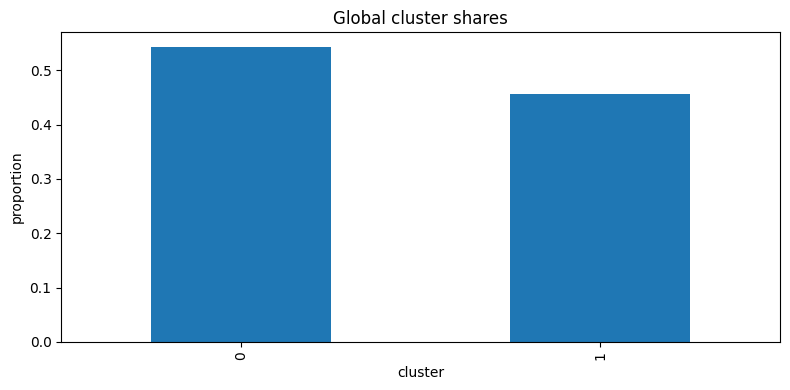

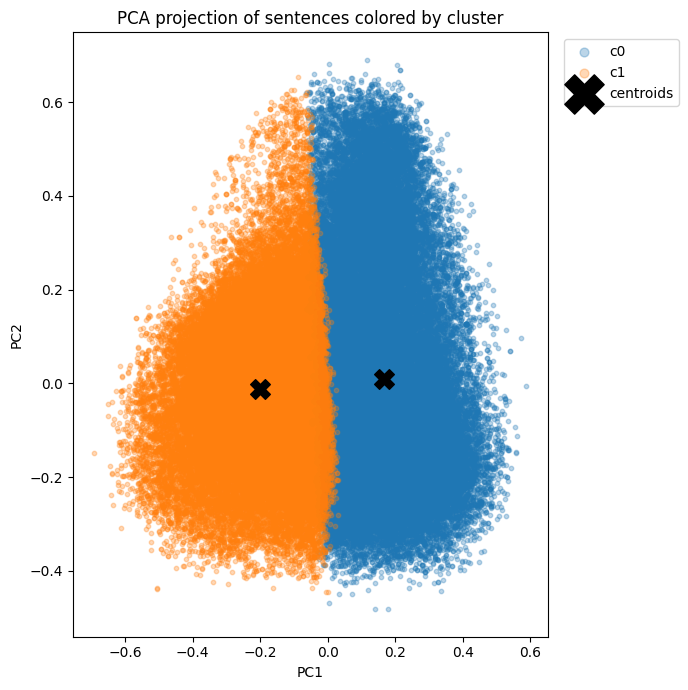

In [26]:
%run 3_step3B_cluster_report_PCA+KMeans.py 

**Method:** We encoded every sentence containing the target using XL-LEXEME’s 1 024-dimensional contextual embeddings, concatenated the yearly matrices into a single N×1024 array, and ℓ2-normalized so cosine similarity equalled Euclidean distance. To reduce noise and speed up clustering, we ran PCA to 100 components (explaining 95.1 % of the variance), then fit K-means for k=2–n, tracking inertia (elbow criterion) and average silhouette. For each k, we saved sentence-cluster assignments, the k×100 centroid matrix, and the top-15 TF-IDF keywords per cluster for interpretability.

**Interpretation:** The inertia curve’s sharpest “elbow” occurred at k=2, while the silhouette score peaked at k=3 (0.092 versus 0.091 at k=4). Prioritizing both parsimony and cohesion, the pipeline selected k=2, revealing two dominant sense clusters. All artifacts are available in output/thematic_content/cluster_XLL_embeddings for rapid thematic inspection and downstream analysis.

#### GLOBAL: Cluster XLL sentence vectors using UMAP + HDBSCAN (sense change tracking) - PAUSED; NEED TO INSTALL PACKAGES ETC

Function: We map each sentence into its high-dimensional XL-LEXEME embedding space, then automatically discover coherent “sense” clusters by first denoising with UMAP and then grouping via HDBSCAN. This captures fine-grained semantic distinctions (e.g. literal vs. metaphorical usages) without a priori specifying the number of clusters or relying on linear projections.

Purpose: Identify and track shifts in the prevalence of distinct sentence‐level senses of our target term over time—using a SOTA clustering pipeline that mirrors Top2Vec/BERTopic under the hood but leverages our custom XLL embeddings.
UMAP dimensionality reduction and HDBSCAN clustering of XLL embeddings (modern SOTA)

Note:
- No manual K selection: HDBSCAN infers the optimal number of clusters and flags outliers.
- Non-linear manifold: UMAP preserves both local and global structure better than PCA, yielding tighter, more semantically coherent clusters.
- Post-hoc labeling: We extract representative keywords per cluster via c-TF-IDF (or centroid proximity) to summarize each sense.

In [16]:
# In a notebook cell:
#%conda install -c conda-forge hdbscan -y
#import hdbscan
#import umap

In [17]:
#%run 3_step3A_cluster-XLL_embeddings_UMAP+HDBSCAN.py

In [12]:
#%run 3_step3B_cluster_report_UMAP+HDBSCAN.py 

#### LOCAL - BY DECADE: Cluster XLL sentence vectors using PCA (sense change tracking)

**Procedure**: For each decade in our target‐mention corpus, we load all XL-LEXEME sentence embeddings, filter out years with too few example (<50 sentences)s, and stack them into one matrix. We ℓ₂-normalize the vectors (so cosine ≡ Euclidean) and optionally reduce them via PCA to 100 dimensions. Next, we grid-search K-Means over k=2–n, using both an inertia “elbow” heuristic and average silhouette score to pick the optimal k (after manual inspection). After fitting K-Means at thatkk, we assign every sentence to a cluster and compute sublinear, smoothed TF-IDF on the raw sentences, then perform a differential ranking (cluster mean minus global mean) to extract the top keywords per cluster. 

Finally, we save for each decade the sentence→cluster table, reduced embeddings, centroids, cluster sizes, top-terms JSON, and a metadata file with PCA variance, chosen kk, and silhouette value.

In [ ]:
%run 3_step3A_cluster-XLL_embeddings_decade.py # using PCA

In [ ]:
%run 3_step3B_cluster_report_decade.py

In [ ]:
%run 3_step3B_plot_centroid_clusters_decade.py

### Topic Modelling
Try options from all-in-one library for topic modeling with sentence embeddings; An all-in-one library for topic modeling with sentence embeddings.
https://github.com/x-tabdeveloping/turftopic
https://x-tabdeveloping.github.io/turftopic/model_overview/
Different models will naturally be good at different things, because they conceptualize topics differently for instance:
1. **SemanticSignalSeparation**: conceptualizes topics as semantic axes, along which topics are distributed. S^3 models are the most balanced(comparing metrics on 20 NewsGroups: https://x-tabdeveloping.github.io/turftopic/model_overview/). Downside is that S^3 is less flexible than BERTopic although it performs well out-of-the-box. https://x-tabdeveloping.github.io/turftopic/s3/
2. **ClusteringTopicModel** finds clusters of documents and treats those as topics
3. **KeyNMF** conceptualizes topics as factors, or looked at it from a different angle, it finds clusters of words

**NOTE**: The quality of the topics you can get out of your topic model can depend on a lot of things, including your choice of vectorizer and encoder model. More rigorous evaluation regimes can be found in a number of studies on topic modeling.

For topic assessment, there's a thing called topic coherence, and people usually plot it against different parameters such as  number of topic to check where the coherence is optimal (see my old tiny paper: https://aclanthology.org/2020.nlpcovid19-2.12.pdf)

The standard metrics for that are UMass and C_v but people are coming up with newer and better metrics: https://aclanthology.org/2024.findings-eacl.123.pdf

### GLOBAL ANALYSIS

Use Semantic Signal Separation as the topic model of choice: https://x-tabdeveloping.github.io/turftopic/s3/

In [4]:
#%run # 

### DECADAL ANALYSIS

Use Semantic Signal Separation as the topic model of choice: https://x-tabdeveloping.github.io/turftopic/s3/

In [ ]:
%run # 

# End of Script